# Refutation flow: ATTE

## Формулы ATTE

- $D_i=1$ — test / treated; $D_i=0$ — control.
- $Y_i$ — outcome, например LTV / PnL; $X_i$ — confounders до treatment.
- $m(X_i)=P(D=1\mid X_i)$ — propensity.
- $g_0(X_i)=E[Y\mid D=0,X_i]$ — outcome model для control.
- $g_1(X_i)=E[Y\mid D=1,X_i]$ — outcome model для treated.
- $p=E[D]$ — доля treated; $n$ — число наблюдений, $n_t=\sum_iD_i$, $\hat p=n_t/n$.

Шляпки обозначают оценки; в ATTE score ниже используется $g_0$.

**ATTE и DML IRM score.**

$$
\theta_{\mathrm{ATTE}}=E[Y(1)-Y(0)\mid D=1].
$$

$$
\begin{aligned}
\psi_i(\theta)
&=-\frac{D_i}{p}\theta+\frac{D_i(Y_i-g_0(X_i))}{p}\\
&\quad-\frac{m(X_i)(1-D_i)(Y_i-g_0(X_i))}{p(1-m(X_i))}.
\end{aligned}
$$

Оценка получается из sample moment с оценёнными nuisance functions:

$$
\frac1n\sum_{i=1}^{n}\hat\psi_i(\hat\theta_{\mathrm{ATTE}})=0,
\qquad
\hat\psi_i(\theta)=\psi_i(\theta;\hat g_0,\hat m,\hat p).
$$

**Две эквивалентные формы estimator.**

$$
\hat\theta_{\mathrm{ATTE}}
=\frac1n\sum_{i=1}^{n}\left[
\frac{D_i}{\hat p}(Y_i-\hat g_0(X_i))
-\frac{\hat m(X_i)(1-D_i)}{\hat p(1-\hat m(X_i))}(Y_i-\hat g_0(X_i))
\right].
$$

$$
\hat\theta_{\mathrm{ATTE}}
=\frac1{n_t}\left[
\sum_{i:D_i=1}(Y_i-\hat g_0(X_i))
-\sum_{i:D_i=0}\frac{\hat m(X_i)}{1-\hat m(X_i)}(Y_i-\hat g_0(X_i))
\right].
$$

**Correction и odds weights.**

$$
\underbrace{\sum_{i:D_i=1}(Y_i-\hat g_0(X_i))}_{\text{treated residuals}}
\; - \;
\underbrace{\sum_{i:D_i=0}\frac{\hat m(X_i)}{1-\hat m(X_i)}(Y_i-\hat g_0(X_i))}_{\text{control correction}}.
$$

Первый член сравнивает outcome treated с predicted counterfactual. Второй корректирует ошибку $\hat g_0$ на control, похожих на treated:

$$
\underbrace{\frac{\hat m(X_i)}{1-\hat m(X_i)}}_{\text{odds weight}}
\underbrace{(Y_i-\hat g_0(X_i))}_{\text{control residual}}.
$$

Сумма control odds weights приближённо восстанавливает число treated:

$$
\sum_{i:D_i=0}\frac{\hat m(X_i)}{1-\hat m(X_i)}\approx n_t.
$$

**Variance, SE и confidence interval для независимых наблюдений.**

Пусть $\hat\psi_i^{\mathrm{ATTE}}=\hat\psi_i(\hat\theta_{\mathrm{ATTE}})$. Тогда

$$
\hat\sigma_{\mathrm{ATTE}}^2
=\frac1n\sum_{i=1}^{n}\left(\hat\psi_i^{\mathrm{ATTE}}\right)^2,
$$

$$
\widehat{SE}(\hat\theta_{\mathrm{ATTE}})
=\frac{\hat\sigma_{\mathrm{ATTE}}}{\sqrt n}
=\sqrt{\frac1{n^2}\sum_{i=1}^{n}\left(\hat\psi_i^{\mathrm{ATTE}}\right)^2}.
$$


$$
\hat\theta_{\mathrm{ATTE}}
\pm z_{1-\alpha/2}\widehat{SE}(\hat\theta_{\mathrm{ATTE}}).
$$

Развёрнутая форма того же confidence interval:

$$
\hat\theta_{\mathrm{ATTE}}\pm z_{1-\alpha/2}
\sqrt{\frac1{n^2}\sum_{i=1}^{n}
\left[\begin{aligned}
&\frac{D_i}{\hat p}\bigl(Y_i-\hat g_0(X_i)-\hat\theta_{\mathrm{ATTE}}\bigr)\\
&-\frac{(1-D_i)\hat m(X_i)}{\hat p(1-\hat m(X_i))}\bigl(Y_i-\hat g_0(X_i)\bigr)
\end{aligned}\right]^2}.
$$

Здесь $z_{1-\alpha/2}$ — quantile стандартного normal distribution.

In [15]:
from causalis.data_contracts import CausalData
from causalis.scenarios.unconfoundedness import IRM
from causalis.scenarios.unconfoundedness.dgp import generate_obs_hte_26_rich
from causalis.scenarios.unconfoundedness.refutation import (
    plot_m_overlap,
    plot_propensity_reliability,
    run_overlap_diagnostics,
)

## Data

Используются 2 датасета: синтетический и настоящий

In [16]:
data = generate_obs_hte_26_rich(
    n=100_000,
    seed=42,
    return_causal_data=False,
    include_oracle=False,
)
data.head()

,user_id,y,d,tenure_months,avg_sessions_week,spend_last_month,age_years,income_monthly,prior_purchases_12m,support_tickets_90d,premium_user,mobile_user,urban_resident,referred_user
0,1,0.000000,0.0,28.814654,1.0,77.936767,50.234101,1926.698301,1.0,2.0,1.0,1.0,1.0,0.0
1,2,80.099611,1.0,25.913345,3.0,53.777740,28.115859,5104.271509,3.0,0.0,1.0,1.0,0.0,1.0
2,3,6.400482,1.0,24.969929,10.0,134.764322,22.907062,5267.938255,8.0,3.0,0.0,1.0,1.0,0.0
3,4,2.788238,0.0,40.655089,5.0,59.517074,31.970490,6597.327018,3.0,2.0,1.0,1.0,1.0,0.0
4,5,0.000000,0.0,18.560899,3.0,74.370930,39.237248,4930.009628,5.0,1.0,1.0,1.0,0.0,0.0


In [17]:
causaldata = CausalData(
    df=data,
    user_id="user_id",
    treatment="d",
    outcome="y",
    confounders=[
        "tenure_months",
        "avg_sessions_week",
        "spend_last_month",
        "age_years",
        "income_monthly",
        "prior_purchases_12m",
        "support_tickets_90d",
        "premium_user",
        "mobile_user",
        "urban_resident",
        "referred_user",
    ],
)
causaldata

CausalData(df=(100000, 14), treatment='d', outcome='y', confounders=['tenure_months', 'avg_sessions_week', 'spend_last_month', 'age_years', 'income_monthly', 'prior_purchases_12m', 'support_tickets_90d', 'premium_user', 'mobile_user', 'urban_resident', 'referred_user'], user_id='user_id')

## Inference ATTE

In [18]:
model = IRM(
    n_jobs=-1,
    random_state=42,
    overlap_policy="clip",
    overlap_threshold=0.01,
).fit(causaldata)

dml_result = model.estimate(score="ATTE")
dml_result.summary()

,value
field,
outcome,y
estimand,ATTE
model,IRM
value,"9.9026 (ci_abs: 4.4731, 15.3320)"
value_relative,"20.3741 (ci_rel: 8.3605, 32.3877)"
alpha,0.0500
p_value,0.0004
is_significant,True
n_treated,4949


## Unconfoundedness

Предпосылка: $(Y(0), Y(1)) \perp D \mid X$ — после учёта confounders $X$ назначение treatment $D$ не зависит от potential outcomes. Интуиция: $X$ достаточно, чтобы устранить confounding при сравнении treated и control.

### SMD

$$
\mathrm{SMD}(X)=\frac{|\bar X_{1,w}-\bar X_{0,w}|}{\sqrt{(s_{1,w}^2+s_{0,w}^2)/2}}.
$$

Здесь $\bar X_{d,w}$ и $s_{d,w}^2$ — weighted mean и weighted variance для группы $d$. Для ATTE веса в treated равны $1$, а в control — $\hat m(X)/(1-\hat m(X))$.

Интуиция: SMD измеряет разницу средних в единицах pooled standard deviation. Чем ближе к нулю, тем лучше covariate balance по среднему этого признака.

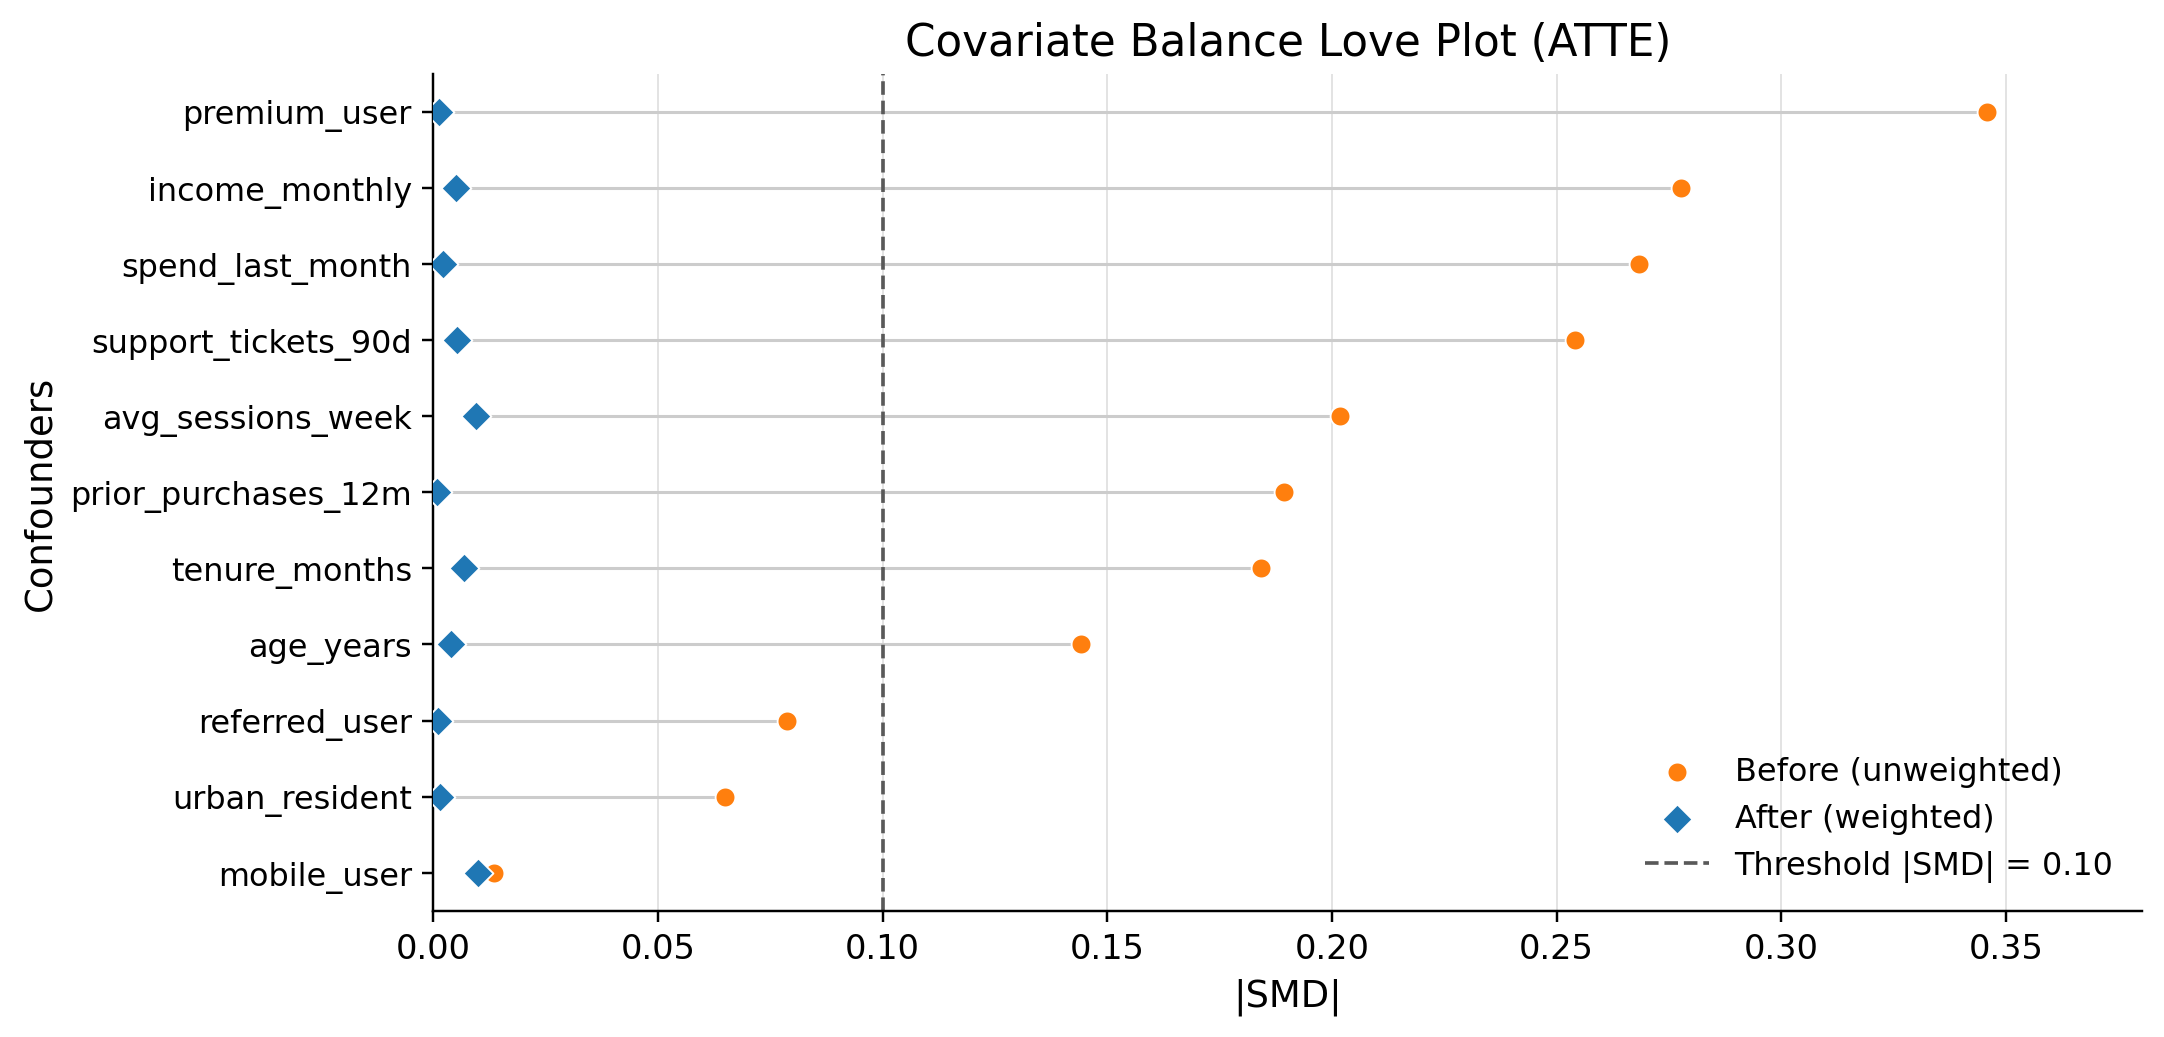

In [23]:
from causalis.scenarios.unconfoundedness.refutation import love_plot

love_plot(causaldata, dml_result)

In [30]:
unc_report = run_unconfoundedness_diagnostics(causaldata, dml_result)
unc_report["summary"]

,metric,value,flag
0,balance_max_smd,0.010018,GREEN
1,balance_frac_violations,0.000000,GREEN


Флаги при `threshold=0.10`:

| metric | 🟢 GREEN | 🟡 YELLOW | 🔴 RED |
| --- | --- | --- | --- |
| `balance_max_smd` | < 0.10 | 0.10 ≤ value < 0.20 | ≥ 0.20 |
| `balance_frac_violations` | < 10% | 10% ≤ value < 25% | ≥ 25% |

`balance_max_smd` — максимальный weighted SMD; `balance_frac_violations` — доля confounders с weighted SMD ≥ `threshold`. `overall_flag` — худший из двух флагов.

## Overlap


Для ATTE пользователям из treated нужны сопоставимые пользователи из control. Веса control (odds weights) равны $m(X)/(1-m(X))$, поэтому при высоком propensity они могут быть большими.

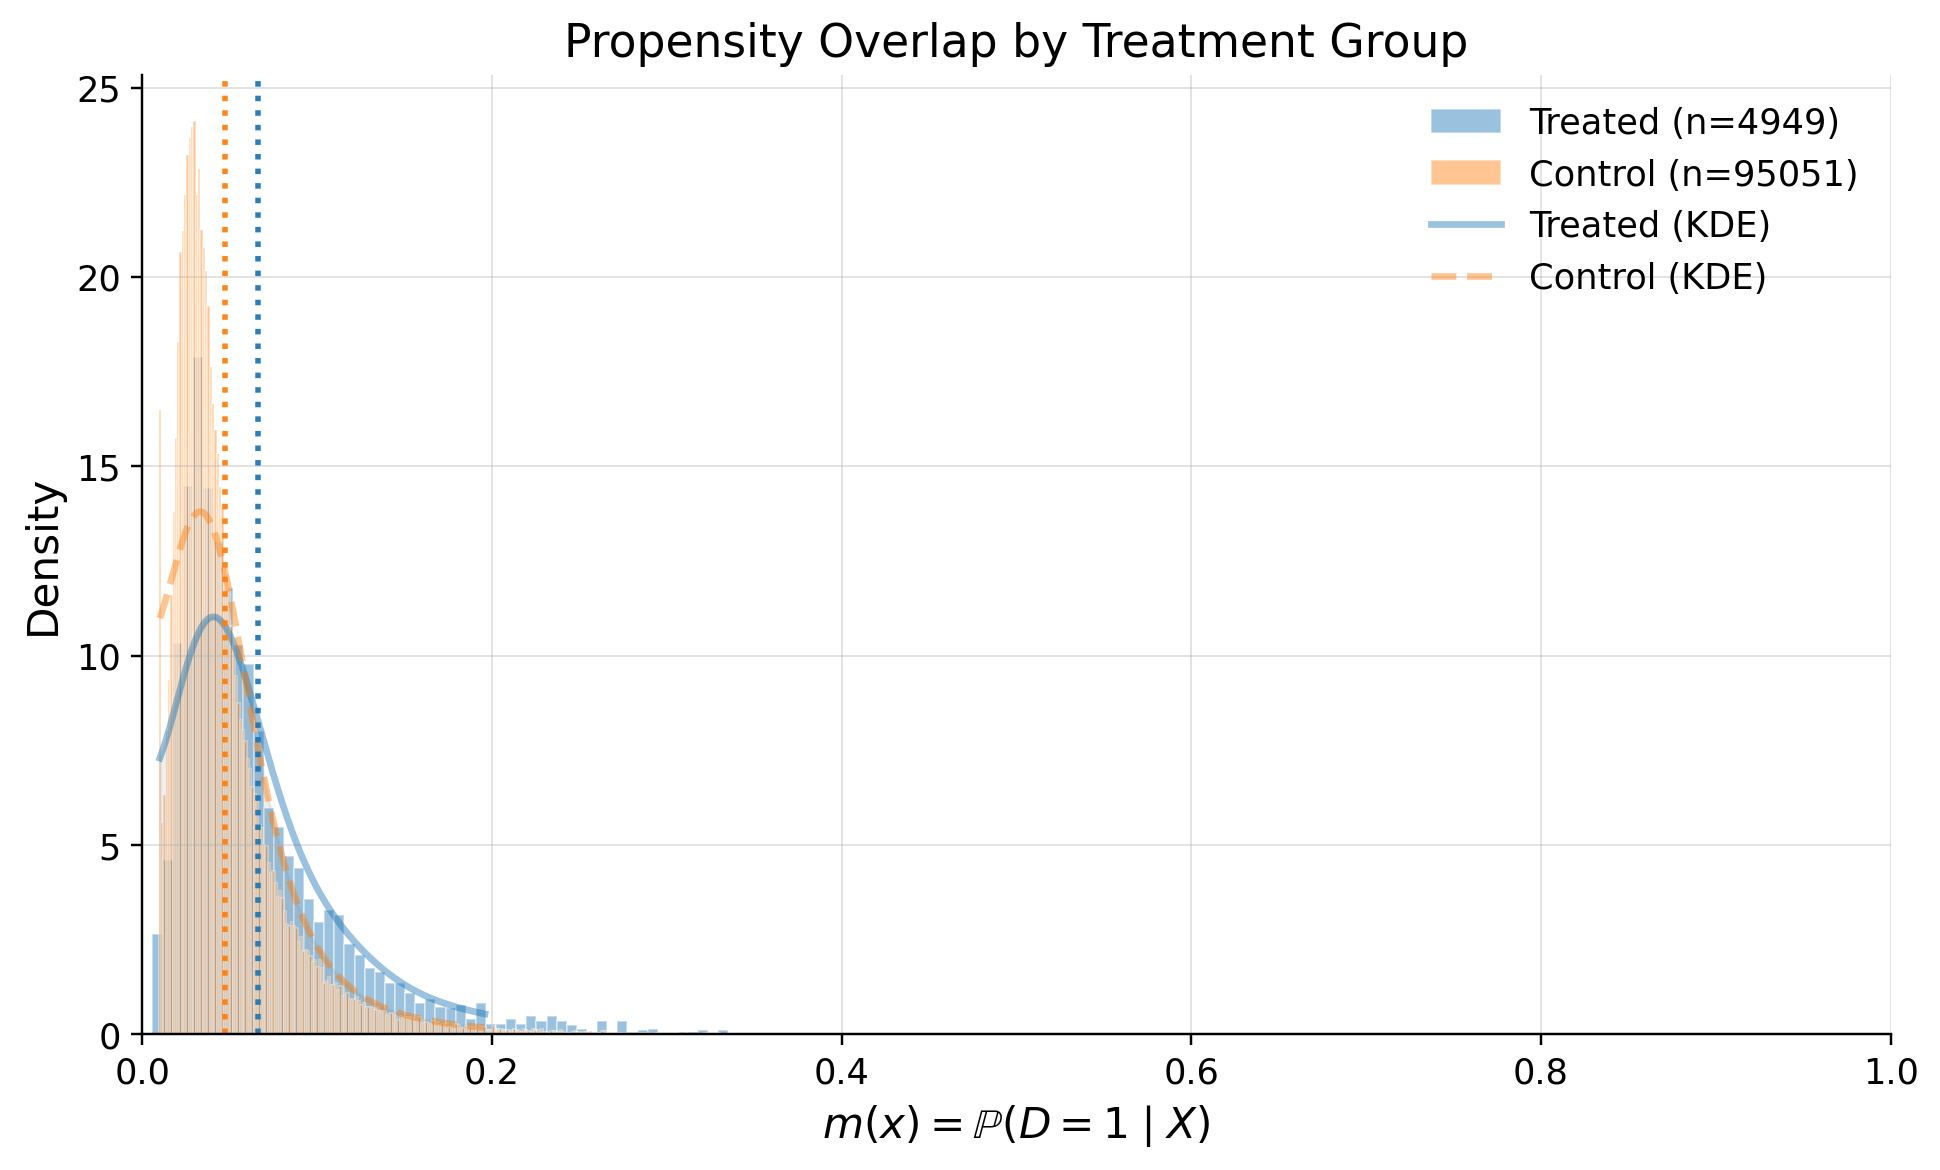

In [31]:
plot_m_overlap(dml_result)

In [ ]:
rep = run_overlap_diagnostics(causaldata, dml_result)

overlap_metrics = [
    "edge_0.01_below",
    "edge_0.01_above",
    "KS",
    "AUC",
    "support_rate",
    "ESS_treated_ratio",
    "ESS_control_ratio",
    "calib_ECE",
]
rep["summary"].set_index("metric").loc[overlap_metrics].reset_index()

Флаги при настройках по умолчанию (`x` — значение metric):

| metric | 🟢 GREEN | 🟡 YELLOW | 🔴 RED |
| --- | --- | --- | --- |
| `edge_0.01_below` | x ≤ 0.02 | 0.02 < x ≤ 0.05 | x > 0.05 |
| `edge_0.01_above` | x ≤ 0.02 | 0.02 < x ≤ 0.05 | x > 0.05 |
| `KS` | x ≤ 0.30 | 0.30 < x ≤ 0.40 | x > 0.40 |
| `AUC` | s ≤ 0.80 | 0.80 < s ≤ 0.90 | s > 0.90 |
| `support_rate` | x ≥ 0.95 | 0.90 ≤ x < 0.95 | x < 0.90 |
| `ESS_treated_ratio` | x ≥ 0.30 | 0.15 ≤ x < 0.30 | x < 0.15 |
| `ESS_control_ratio` | x ≥ 0.30 | 0.15 ≤ x < 0.30 | x < 0.15 |
| `calib_ECE` | x ≤ 0.10 | 0.10 < x ≤ 0.20 | x > 0.20 |

У двух edge-строк общий flag: здесь `x` — максимум `edge_0.01_below` и `edge_0.01_above`. Для `AUC` используется `s = max(AUC, 1 - AUC)`.

В этой реализации `ESS_*_ratio` используют ATE weights: $1/m(X)$ для treated и $1/(1-m(X))$ для control, даже при ATTE.

**Общие входные данные для расчётов ниже.** Берём сохранённые predictions из `dml_result.diagnostic_data`: propensity `m_hat_raw` (при его отсутствии — `m_hat`) и treatment `d` в том же порядке строк. Исключаем строки, где выбранный propensity, `m_hat` или `d` содержат `NaN` или infinity. Для численной устойчивости ограничиваем propensity: $m_i\leftarrow\operatorname{clip}(m_i,10^{-12},1-10^{-12})$. Это вход для KS, AUC, ESS и ECE; для support применяется дополнительный clip перед logit. Далее $n_1$ и $n_0$ — размеры treated и control после фильтрации, $n=n_1+n_0$.

**KS.** $KS=\sup_t|F_1(t)-F_0(t)|$, где $F_d$ — empirical CDF raw propensity $m_i=\hat m(X_i)$ в группе $d$. Интуиция: максимальный разрыв распределений; меньше — слабее разделение treated/control.

Шаги расчёта:

1. Разделить propensity на две группы по $D_i$: treated при $D_i=1$, control при $D_i=0$. Посчитать размеры $n_1,n_0$ и отсортировать значения внутри каждой группы.
2. Построить сетку $T$ из всех уникальных propensity обеих групп. Этой сетки достаточно: между соседними точками empirical CDF постоянны.
3. Для каждого $t\in T$ посчитать $k_1(t)$ и $k_0(t)$ — сколько propensity в каждой группе не превышает $t$. Значения, равные $t$, тоже включаются.
4. Разделить эти количества на размеры своих групп: $F_1(t)=k_1(t)/n_1$, $F_0(t)=k_0(t)/n_0$. Это накопленные доли наблюдений с propensity $\le t$.
5. В каждой точке найти $\Delta(t)=|F_1(t)-F_0(t)|$, затем взять $KS=\max_{t\in T}\Delta(t)$. Получится KS statistic в диапазоне $[0,1]$.

Пример: treated $[0.2,0.6]$, control $[0.2,0.3]$. На сетке $T=\{0.2,0.3,0.6\}$ разрывы равны $0,0.5,0$, поэтому $KS=0.5$. При $t=0.3$ в treated накоплена половина наблюдений, а в control — все.

**AUC.** $AUC=P(m_1>m_0)+\frac12P(m_1=m_0)$ для случайных treated/control. Интуиция: насколько propensity различает группы; около $0.5$ — слабое разделение, около $0$ или $1$ — сильное.

Шаги расчёта:

1. Выделить propensity treated и control, посчитать $n_1,n_0$. Отсортировать propensity control, чтобы быстро находить, сколько значений меньше или равно заданному.
2. Для каждого treated $i$ найти $L_i=\#\{j:D_j=0,\ m_j<m_i\}$ — число control, у которых propensity строго ниже.
3. Отдельно найти $E_i=\#\{j:D_j=0,\ m_j=m_i\}$ — число ties. Сравнение с меньшим propensity даёт $1$ балл, tie — $0.5$, с большим — $0$.
4. Посчитать вклад каждого treated: $q_i=L_i+E_i/2$. Сложить вклады по всем treated: $W=\sum_{i:D_i=1}q_i$.
5. Разделить на общее число возможных пар: $AUC=W/(n_1n_0)$. Сортировка позволяет получить этот результат без создания таблицы всех пар.

Пример из KS: для treated с $m=0.2$ вклад равен $0.5$ из-за tie, а с $m=0.6$ — $2$. Всего четыре пары, поэтому $AUC=(0.5+2)/4=0.625$.

**support_rate (ATTE).** $\frac{1}{n_1}\sum_{i:D_i=1}\mathbf1\{\min_{j:D_j=0}|z_i-z_j|\le c\}$, где $n_1$ — число treated, $z_i=\operatorname{logit}(m_i)$, $c=0.2s_{\mathrm{pool}}$ (pooled within-group SD). Интуиция: доля treated с близким control; выше — больше support.

Шаги расчёта:

1. Для этого расчёта дополнительно ограничить propensity диапазоном $[10^{-8},1-10^{-8}]$. Для каждого наблюдения вычислить logit: $z_i=\log(m_i/(1-m_i))$. Расстояния далее считаются по $z$, в logit-propensity space.
2. В treated и control найти средние $\bar z_1,\bar z_0$ и sample variances $s_d^2=\frac{1}{n_d-1}\sum_{i:D_i=d}(z_i-\bar z_d)^2$. В каждой группе нужно минимум два наблюдения; делитель равен $n_d-1$.
3. Объединить variances с учётом размеров групп: $s_{\mathrm{pool}}^2=\frac{(n_1-1)s_1^2+(n_0-1)s_0^2}{n_1+n_0-2}$. Взять квадратный корень, получив pooled within-group SD $s_{\mathrm{pool}}$.
4. Задать caliper $c=0.2s_{\mathrm{pool}}$: это максимальное расстояние до control, при котором treated считается supported.
5. Для каждого treated $i$ найти ближайший control по logit: $\delta_i=\min_{j:D_j=0}|z_i-z_j|$. Один control может давать support нескольким treated; после сравнения он остаётся доступным.
6. Присвоить $I_i=1$, если $\delta_i\le c$, иначе $I_i=0$. Равенство расстояния caliper тоже засчитывается.
7. Для ATTE усреднить индикаторы только по treated: $support\_rate=\sum_{i:D_i=1}I_i/n_1$.

Пример: если из $100$ treated у $95$ есть control в пределах caliper, то $support\_rate=95/100=0.95$.

**ESS_treated_ratio.** $\frac{(\sum_{i:D_i=1}w_i)^2}{n_1\sum_{i:D_i=1}w_i^2}$, где $w_i=1/m_i$, $n_1$ — число treated. Интуиция: $1$ — равномерные weights; низкое значение — доминирование немногих treated.

Шаги расчёта:

1. Оставить наблюдения treated ($D_i=1$) и посчитать их число $n_1$.
2. Для каждого treated вычислить ATE weight $w_i=1/m_i$. Например, propensity $0.1$ даёт weight $10$, а $0.5$ — weight $2$: редкие для treated профили получают больший вес.
3. Сложить weights внутри treated: $S_1=\sum_{i:D_i=1}w_i$. Отдельно возвести каждый weight в квадрат и сложить: $Q_1=\sum_{i:D_i=1}w_i^2$.
4. Вычислить Kish ESS: $\mathrm{ESS}_1=S_1^2/Q_1$. Большие отдельные weights сильнее увеличивают сумму квадратов и снижают ESS.
5. Разделить на размер группы: $ESS\_treated\_ratio=\mathrm{ESS}_1/n_1$. При одинаковых weights ratio равен $1$; при концентрации почти всего веса на одном наблюдении приближается к $1/n_1$.

Пример: propensity treated $[0.5,0.5,0.25]$ дают weights $[2,2,4]$. Тогда $S_1=8$, $Q_1=24$, $\mathrm{ESS}_1=64/24\approx2.67$, а ratio $=64/(24\cdot3)=8/9\approx0.889$.

Здесь измеряется концентрация ATE weights по наблюдениям; эти weights используются в данном diagnostic и при ATTE. Нормировка всех weights группы одним множителем ratio не меняет.

**ESS_control_ratio.** $\frac{(\sum_{i:D_i=0}w_i)^2}{n_0\sum_{i:D_i=0}w_i^2}$, где $w_i=1/(1-m_i)$, $n_0$ — число control. Интуиция: $1$ — равномерные weights; низкое значение — доминирование немногих control.

Шаги расчёта:

1. Оставить наблюдения control ($D_i=0$) и посчитать их число $n_0$.
2. Для каждого control вычислить ATE weight $w_i=1/(1-m_i)$. Например, propensity $0.9$ даёт weight $10$, а $0.5$ — weight $2$: редкие для control профили получают больший вес.
3. Найти сумму weights $S_0=\sum_{i:D_i=0}w_i$ и сумму их квадратов $Q_0=\sum_{i:D_i=0}w_i^2$.
4. Вычислить Kish ESS: $\mathrm{ESS}_0=S_0^2/Q_0$. Если несколько control имеют очень большие weights, ESS уменьшается относительно числа control.
5. Разделить на размер группы: $ESS\_control\_ratio=\mathrm{ESS}_0/n_0$. При одинаковых weights ratio равен $1$; при доминировании одного control приближается к $1/n_0$.

Пример: propensity control $[0.5,0.5,0.875]$ дают weights $[2,2,8]$. Тогда $S_0=12$, $Q_0=72$, $\mathrm{ESS}_0=144/72=2$, а ratio $=2/3\approx0.667$.

В этом diagnostic используются ATE weights $1/(1-m_i)$; control odds weights для ATTE равны $m_i/(1-m_i)$.

**calib_ECE.** $\mathrm{ECE}=\sum_b\frac{n_b}{n}|\bar D_b-\bar m_b|$ по bins propensity равной ширины; $n_b$ — число наблюдений в bin. Интуиция: средний разрыв predicted propensity и фактической доли treated; меньше — лучше calibration.

Шаги расчёта:

1. Выбрать число bins $B=\texttt{n\_bins}$; по умолчанию $B=10$. Разбить диапазон propensity $[0,1]$ на bins равной ширины $1/B$.
2. Отнести каждое наблюдение к bin с индексом $b_i=\min(\lfloor Bm_i\rfloor,B-1)$. При $B=10$ интервалы имеют вид $[0,0.1),[0.1,0.2),\ldots,[0.9,1]$: значение на внутренней границе попадает в bin справа.
3. В каждом bin посчитать $n_b$ — число наблюдений. Пустые bins пропустить; общее число наблюдений обозначить $n=\sum_b n_b$.
4. Для каждого непустого bin вычислить средний predicted propensity $\bar m_b=\frac1{n_b}\sum_{i:b_i=b}m_i$ и фактическую долю treated $\bar D_b=\frac1{n_b}\sum_{i:b_i=b}D_i$.
5. Найти абсолютную calibration error этого bin: $e_b=|\bar D_b-\bar m_b|$.
6. Взвесить ошибки долями наблюдений и сложить: $\mathrm{ECE}=\sum_b(n_b/n)e_b$. Так bin с большим числом наблюдений сильнее влияет на итог.

Пример: в bin $20$ наблюдений из общих $100$, средний predicted propensity равен $0.15$, а доля treated — $0.25$. Ошибка bin равна $0.10$, его вклад в ECE — $(20/100)\cdot0.10=0.02$. Для полного ECE нужно сложить вклады всех непустых bins.

### Sensitivity (В следующий раз)

By default, `rank_confounder_clusters(...).head(3)` selects two clusters by `importance_d * importance_y`, then the cluster with the highest `importance_d` among those not already selected. This reuses existing importances without extra model fits. Scores are unchanged, but mixed ordering is not necessarily descending by score. Use `ranking_method="joint"` to restore the previous ordering. This is a screening heuristic and does not guarantee higher benchmark `r2_d`.

These clusters group correlated **confounder columns**, not observational units. The ATTE fit continues to use non-clustered inference.

In [24]:
from causalis.shared import rank_confounder_clusters

ranking = rank_confounder_clusters(
    causaldata,
    dml_result,
    min_abs_correlation=0.5,
    correlation_method="pearson",
    linkage_method="complete",
    max_samples=200_000,
    random_state=42,
)

top3 = ranking.head(3)

benchmark_groups = {
    f"rank_{rank}_cluster_{row['cluster_id']}": list(row["features"])
    for rank, (_, row) in enumerate(top3.iterrows(), start=1)
}

In [25]:
top3

,cluster_id,features,n_features,importance_d,importance_g0,importance_g1,importance_y,score
0,1,[avg_sessions_week],1,0.092340,0.279259,0.200673,0.239966,0.022158
1,0,[tenure_months],1,0.164019,0.116581,0.106571,0.111576,0.018301
2,2,[spend_last_month],1,0.175976,0.068335,0.075962,0.072149,0.012696


The protocol compares every primary benchmark's bias-aware interval with the decision threshold. Here 0 tests whether the ATTE remains positive; choose a practically meaningful threshold for your application. Stress and adversarial scenarios describe the robustness margin.

As in the scenario notebook, `preconditions_passed=True` is an illustrative external assumption that the adjustment set, design, overlap, nuisance quality, and estimator stability have been reviewed and accepted. Set it to `False` when a prerequisite is unresolved. A sensitivity PASS is conditional on that gate and the chosen benchmarks.

In [26]:
from causalis.scenarios.unconfoundedness.refutation import (
    run_sensitivity_protocol
)

protocol = run_sensitivity_protocol(
    dml_result,
    causaldata,
    benchmark_groups=benchmark_groups,
    decision_threshold=0.0,  # Or your minimum practically meaningful effect.
    direction="auto",
    preconditions_passed=True,
)

print(protocol["status"])
print(protocol["summary"])

# protocol["primary"]
# protocol["stress"]
# protocol["adversarial"]
# protocol["warnings"]

PASS
PASS: the practically meaningful effect is robust to hidden confounding comparable to every primary benchmark. Every primary bias-aware confidence interval satisfies the positive decision rule (ci_lower > 0). The reported stress-test margin is limited. DoubleML boundary calibration was used for ['rank_2_cluster_0', 'rank_3_cluster_2'].


In [27]:
protocol["primary"]

,benchmark,benchmark_group,scenario,multiplier,r2_y,r2_d,rho,theta_long,theta_short,delta,relative_delta,theta_lower,theta_upper,ci_lower,ci_upper,rv,rva,scenario_valid,scenario_issue,passed
0,rank_1_cluster_1,"(avg_sessions_week,)",primary,1.0,0.345836,0.004704,-0.038902,9.902561,8.578262,1.324299,0.133733,8.572018,11.233104,3.145062,16.668285,0.259010,0.126871,True,None,True
1,rank_2_cluster_0,"(tenure_months,)",primary,1.0,0.053420,0.000000,1.000000,9.902561,12.229947,-2.327386,0.235029,9.902561,9.902561,4.473129,15.331993,0.011637,0.005268,True,None,True
2,rank_3_cluster_2,"(spend_last_month,)",primary,1.0,0.012534,0.000000,1.000000,9.902561,11.168087,-1.265526,0.127798,9.902561,9.902561,4.473129,15.331993,0.011637,0.005268,True,None,True
